# Energy Scores by Distance Group

This notebook combines the study classification logic from `distance_distributions.ipynb` with the energy-score aggregation pattern from `energy_score_by_hand.ipynb`.

Definitions used here:

- `MoveBench Studies V2.csv` defines the true study roster for inclusion/exclusion accounting.
- Local study directories that are not present in V2 are excluded up front and reported separately.
- V2 study names are mapped onto local study directories with direct matches when possible plus a small manual override table for the human-readable study names that do not match on-disk IDs.
- Study distance is the study-level median of each individual's maximum net displacement from its first fix.
- Shared distance cutoffs are `short < 12 km`, `medium < 650 km`, `long >= 650 km`.
- Any completed current-planned `main_results` `test_temporal` run at any timescale is eligible. A study does not need all four timescales to contribute.
- A method/timescale contributes only when that study also has a `baseline_nomove` score at the same timescale, because normalization is done study-by-study before averaging.

The six requested panels are:

1. Bird short+medium
2. Bird long
3. Reptiles all
4. Mammal short
5. Mammal medium+long
6. Marine all


In [1]:
from pathlib import Path
import csv
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from movebench import paths
import movebench.bench.run as bench_run
import movebench.bench.run_state as bench_run_state
from movebench.trajectories import (
    INDIVIDUAL_COL,
    LAT_COL,
    LON_COL,
    TIME_COL,
    haversine_distance_m,
    load_trajectories_csv,
)

warnings.filterwarnings("ignore", category=pd.errors.DtypeWarning)
sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_rows", 200)


/data/vision/beery/scratch/justin/micromamba/envs/movebench/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
RUNS_ROOT = paths.repo_root() / "results" / "bench" / "runs"
STUDIES_V2_PATH = paths.repo_root() / "MoveBench Studies V2.csv"
TRAITS_PATH = paths.repo_root().parent / "movebench-figures" / "outputs" / "traits" / "movebench_traits.csv"

PLOT_METHODS = ["baseline_randomwalk",
                "issf_linear", 
                "issf_mlp", 
                "deepssf", 
                "moveformer"]
NORMALIZE_BY = "baseline_nomove"
REQUIRED_METHODS = [NORMALIZE_BY, *PLOT_METHODS]
TIMESCALE_ORDER = ["1h", "12h", "1d", "7d"]
SPLIT_KEY = "test_temporal"

SHORT_KM = 25.0
LONG_KM = 650.0

STUDY_ID_OVERRIDES = {
    ("Antarctic Petrel", "Thalassoica antarctica"): "klappstein2024_smoothSSF_data_petrel",
    ("Fiedler_0a3ec70a; Fiedler_520a64ae; Fiedler_5f8c5199", "Ciconia ciconia"): "Fiedler_lifetrack_stork_all",
    ("Klzsch_22d42221; Klzsch_2e9dace9", "Anser albifrons"): "Klzsch_22d42221_2e9dace9_all",
    ("AMT Deer", "Cervus elaphus"): "amtdeer_wgs84",
    ("Alaska Sea Lion", "Eumetopias jubatus"): "wilson2018_sea_lion_telemetry",
    ("Australia water buffalo", "Bubalus bubalis"): "forrest2024_buffalo",
    ("Botswana Hyena", "Crocuta crocuta"): "cazzi2016_hyena",
    ("Colorado Mountain Lion", "Puma concolor"): "hooten2018_mountain_lion_AM80",
    ("Desert Pronghorn", "Antilocapra americana"): "aikens2025_pronghorn",
    ("Elephant seal", "Mirounga angustirostris"): "costa2024_elephant_seals",
    ("Illinois Deer", "Odocoileus virginianus"): "egan2025_deer",
    ("Kenya Wildebeast", "Connochaetes taurinus"): "stabach2020_wildebeest",
    ("Mississippi Pig", "Sus scrofa"): "potts2022_pig",
    ("Mountain Pronghorn", "Antilocapra americana"): "aikens2024_pronghorn",
    ("Namibia Elephants", "Loxodonta africana"): "killian_elephants",
    ("Tsavo Lions", "Panthera leo"): "tsavo_lions",
}

# PANEL_ORDER = [
#     "bird_short_medium",
#     "bird_long",
#     "reptiles_all",
#     "mammal_short",
#     "mammal_medium_long",
#     "marine_all",
# ]

PANEL_ORDER = [
    "bird_short_medium",
    "bird_long",
    
    "mammal_short",
    "mammal_medium_long",
    
    "marine_all",
    "reptiles_all",
]

# Median max displacement
# SHORT_KM = 25.0
# LONG_KM = 650.0
PANEL_TITLES = {
    "bird_short_medium": "Bird < 650km ",
    "bird_long": "Bird > 650km",
    "reptiles_all": "Terrestrial Reptile",
    "mammal_short": "Mammal < 25km",
    "mammal_medium_long": "Mammal > 25km",
    "marine_all": "Marine",
}
METHOD_COLORS = {
    "baseline_randomwalk": "#363636",
    "issf_linear": "#c1121f",
    "issf_mlp": "#f77f00",
    "deepssf": "#003049",
    "moveformer": "#669bbc",
}
COVARIATE_COMPARISON_METHODS = ["issf_linear", "issf_mlp", "deepssf", "moveformer"]
COVARIATE_SET_ORDER = ["lite", "all_environmental", "alphaearth_only", "alphaearth_and_marine", "all",]
COVARIATE_COLORS = {
    "lite": "#ADCFFF",
    "all_environmental": "#3a8cff",
    "alphaearth_only": "#288077",
    "alphaearth_and_marine": "#1b9aaa",
    "all": "#00409a",
}

print(f"Runs root: {RUNS_ROOT}")
print(f"Studies V2 CSV: {STUDIES_V2_PATH}")
print(f"Traits CSV: {TRAITS_PATH}")


def planned_run_map(*experiment_names: str, study_ids: list[str] | None = None) -> dict[str, dict[str, object]]:
    wanted_studies = None if study_ids is None else {str(study_id) for study_id in study_ids}
    selected_experiments = {str(name) for name in experiment_names}
    planned_runs: dict[str, dict[str, object]] = {}

    for entry in bench_run.expanded_checked_in_experiments():
        experiment = dict(entry.get("experiment", {}))
        if str(experiment.get("name", "")) not in selected_experiments:
            continue
        for run in entry.get("runs", []):
            run_payload = dict(run)
            study_id = str(run_payload.get("study_id", ""))
            if wanted_studies is not None and study_id not in wanted_studies:
                continue
            planned_runs[str(run_payload["run_key"])] = run_payload

    return planned_runs


def completed_planned_runs(*experiment_names: str, study_ids: list[str] | None = None) -> dict[str, dict[str, object]]:
    planned_runs = planned_run_map(*experiment_names, study_ids=study_ids)
    latest_run_records = bench_run_state.search_latest_run_records_by_key(list(planned_runs.keys()))
    completed_runs: dict[str, dict[str, object]] = {}

    for run_key, run_payload in planned_runs.items():
        latest_run = dict(latest_run_records.get(run_key, {}))
        if str(latest_run.get("status", "")) != "completed":
            continue
        completed_runs[run_key] = {
            "run_payload": run_payload,
            "latest_run": latest_run,
        }

    return completed_runs


def completed_at_for_run(latest_run: dict[str, object], artifact_paths: list[Path]) -> float:
    end_time = latest_run.get("end_time")
    if isinstance(end_time, (int, float)):
        return float(end_time) / 1000.0
    return float(max(path.stat().st_mtime for path in artifact_paths))


Runs root: /data/vision/beery/scratch/justin/movebench/results/bench/runs
Studies V2 CSV: /data/vision/beery/scratch/justin/movebench/MoveBench Studies V2.csv
Traits CSV: /data/vision/beery/scratch/justin/movebench-figures/outputs/traits/movebench_traits.csv


In [3]:
def _method_label(method_key: str) -> str:
    return str(method_key).replace("baseline","").replace("_", " ").replace("randomwalk", "crw")

In [4]:


DETAIL_GROUP_OVERRIDES = {
    ("Setyawan_0425c92c", "Mobula"): "Marine Sharks and Rays",
    ("Botswana Hyena", "Crocuta crocuta"): "Terrestrial Mammals",
}


def load_group_lookup(traits_path: Path) -> dict[str, str]:
    group_lookup: dict[str, str] = {}
    with traits_path.open(newline="") as f:
        for row in csv.DictReader(f):
            group = row["group"].strip()
            if not group:
                continue

            corrected = row["study_species"].strip()
            original = row["study_species_original"].strip()

            if corrected:
                group_lookup[corrected] = group
            if original:
                group_lookup[original] = group

    for species, group in list(group_lookup.items()):
        if group == "Mammals":
            group_lookup[species] = "Terrestrial Mammals"

    group_lookup["Bubalus bubalis"] = "Freshwater Mammals"
    group_lookup["Mobula"] = "Marine Sharks and Rays"
    return group_lookup


def collapse_high_level_group(detail_group: str | float | None) -> str | None:
    if not isinstance(detail_group, str) or not detail_group:
        return None
    if detail_group.startswith("Marine"):
        return "Marine"
    if "Bird" in detail_group:
        return "Birds"
    if "Mammal" in detail_group:
        return "Terrestrial mammals"
    if "Reptile" in detail_group:
        return "Reptiles"
    return None


def classify_distance_bin(distance_km: float) -> str:
    if float(distance_km) < SHORT_KM:
        return "short"
    if float(distance_km) < LONG_KM:
        return "medium"
    return "long"


def assign_panel(high_level_group: str, distance_bin: str) -> str | None:
    if high_level_group == "Birds":
        return "bird_short_medium" if distance_bin in {"short", "medium"} else "bird_long"
    if high_level_group == "Reptiles":
        return "reptiles_all"
    if high_level_group == "Terrestrial mammals":
        return "mammal_short" if distance_bin == "short" else "mammal_medium_long"
    if high_level_group == "Marine":
        return "marine_all"
    return None


def _species_suffix(study_species: str) -> str:
    return str(study_species).strip().replace(" ", "_")


def _resolve_study_id(study_name: str, study_species: str, available_study_ids: set[str]) -> str | None:
    override = STUDY_ID_OVERRIDES.get((study_name, study_species))
    if override:
        return override
    if study_name in available_study_ids:
        return study_name

    prefix_matches = [
        study_id
        for study_id in available_study_ids
        if study_id.startswith(f"{study_name}_") or study_id.startswith(study_name)
    ]
    if len(prefix_matches) == 1:
        return prefix_matches[0]

    species_matches = [study_id for study_id in prefix_matches if _species_suffix(study_species) in study_id]
    if len(species_matches) == 1:
        return species_matches[0]

    return None


def load_v2_study_roster() -> pd.DataFrame:
    available_study_ids = {path.name for path in paths.studies_root().iterdir() if path.is_dir()}
    group_lookup = load_group_lookup(TRAITS_PATH)

    rows: list[dict[str, object]] = []
    with STUDIES_V2_PATH.open(newline="") as f:
        for row in csv.DictReader(f):
            study_name = str(row["study_name"]).strip()
            study_species = str(row["study_species"]).strip()
            if not study_name or not study_species:
                continue

            study_id = _resolve_study_id(study_name, study_species, available_study_ids)
            detail_group = DETAIL_GROUP_OVERRIDES.get((study_name, study_species), group_lookup.get(study_species))
            high_level_group = collapse_high_level_group(detail_group)
            rows.append(
                {
                    "study_name_v2": study_name,
                    "study_id": study_id,
                    "study_species": study_species,
                    "study_species_common": str(row["study_species_common"]).strip(),
                    "detail_group": detail_group,
                    "high_level_group": high_level_group,
                }
            )

    roster_df = pd.DataFrame.from_records(rows)
    return roster_df.sort_values(["study_name_v2", "study_species"]).reset_index(drop=True)


def compute_individual_distances(study_id: str) -> pd.DataFrame:
    trajectories_path = paths.study_dir(study_id) / "trajectories.csv"
    if not trajectories_path.exists():
        return pd.DataFrame(columns=["individual_id", "max_nsd_m2", "n_points", "max_net_displacement_km"])

    df = load_trajectories_csv(trajectories_path)
    df = df.dropna(subset=[INDIVIDUAL_COL, LAT_COL, LON_COL, TIME_COL]).copy()
    if df.empty:
        return pd.DataFrame(columns=["individual_id", "max_nsd_m2", "n_points", "max_net_displacement_km"])

    df = df.sort_values([INDIVIDUAL_COL, TIME_COL]).reset_index(drop=True)
    df["start_lat"] = df.groupby(INDIVIDUAL_COL, sort=False)[LAT_COL].transform("first")
    df["start_lon"] = df.groupby(INDIVIDUAL_COL, sort=False)[LON_COL].transform("first")
    df["nsd_m2"] = haversine_distance_m(
        df["start_lat"].to_numpy(),
        df["start_lon"].to_numpy(),
        df[LAT_COL].to_numpy(),
        df[LON_COL].to_numpy(),
    ) ** 2

    by_individual = (
        df.groupby(INDIVIDUAL_COL, sort=False)
        .agg(max_nsd_m2=("nsd_m2", "max"), n_points=(INDIVIDUAL_COL, "size"))
        .reset_index()
        .rename(columns={INDIVIDUAL_COL: "individual_id"})
    )
    by_individual = by_individual[by_individual["n_points"] >= 2].copy()
    if by_individual.empty:
        return pd.DataFrame(columns=["individual_id", "max_nsd_m2", "n_points", "max_net_displacement_km"])

    by_individual["max_net_displacement_km"] = np.sqrt(by_individual["max_nsd_m2"]) / 1000.0
    return by_individual


def compute_study_distance_summary(study_roster_df: pd.DataFrame) -> pd.DataFrame:
    rows: list[dict[str, object]] = []

    for row in study_roster_df.itertuples(index=False):
        if not isinstance(row.study_id, str) or not row.study_id:
            continue
        if not isinstance(row.high_level_group, str) or not row.high_level_group:
            continue

        individual_df = compute_individual_distances(row.study_id)
        if individual_df.empty:
            continue

        median_max_displacement_km = float(individual_df["max_net_displacement_km"].median())
        distance_bin = classify_distance_bin(median_max_displacement_km)
        panel = assign_panel(str(row.high_level_group), distance_bin)
        if panel is None:
            continue

        rows.append(
            {
                "study_id": row.study_id,
                "median_max_displacement_km": median_max_displacement_km,
                "distance_bin": distance_bin,
                "panel": panel,
                "n_individuals": int(len(individual_df)),
            }
        )

    return pd.DataFrame.from_records(rows)


def compute_individual_split_summary(study_roster_df: pd.DataFrame) -> pd.DataFrame:
    rows: list[dict[str, object]] = []

    for row in study_roster_df.itertuples(index=False):
        if not isinstance(row.study_id, str) or not row.study_id:
            continue
        if not isinstance(row.high_level_group, str) or not row.high_level_group:
            continue

        individual_df = compute_individual_distances(row.study_id)
        if individual_df.empty:
            continue

        individual_df["distance_bin"] = individual_df["max_net_displacement_km"].map(classify_distance_bin)
        individual_df["panel"] = individual_df["distance_bin"].map(
            lambda distance_bin: assign_panel(str(row.high_level_group), distance_bin)
        )

        panel_counts = (
            individual_df.dropna(subset=["panel"])
            .groupby("panel", as_index=False)
            .size()
            .rename(columns={"size": "n_individuals"})
        )
        for panel_row in panel_counts.itertuples(index=False):
            rows.append(
                {
                    "study_id": row.study_id,
                    "panel": panel_row.panel,
                    "n_individuals": int(panel_row.n_individuals),
                }
            )

    return pd.DataFrame.from_records(rows)


v2_study_df = load_v2_study_roster()
distance_df = compute_study_distance_summary(v2_study_df)
individual_splits_df = compute_individual_split_summary(v2_study_df)

local_study_ids = sorted(path.name for path in paths.studies_root().iterdir() if path.is_dir())
v2_study_ids = sorted(study_id for study_id in v2_study_df["study_id"].dropna().unique())
local_studies_not_in_v2_df = pd.DataFrame(
    {"study_id": [study_id for study_id in local_study_ids if study_id not in set(v2_study_ids)]}
)

study_status_df = v2_study_df.merge(distance_df, on="study_id", how="left")
study_status_df.head()


,study_name_v2,study_id,study_species,study_species_common,detail_group,high_level_group,median_max_displacement_km,distance_bin,panel,n_individuals
0,AMT Deer,amtdeer_wgs84,Cervus elaphus,Red deer,Terrestrial Mammals,Terrestrial mammals,6.406635,short,mammal_short,1.0
1,Accio_967b7813,Accio_967b7813_raw_merged,Ciconia ciconia,White stork,Terrestrial Birds,Birds,2576.805138,long,bird_long,5.0
2,Alaska Sea Lion,wilson2018_sea_lion_telemetry,Eumetopias jubatus,Steller sea lion,Marine Mammals,Marine,184.984408,medium,marine_all,3.0
3,Antarctic Petrel,klappstein2024_smoothSSF_data_petrel,Thalassoica antarctica,Petrel,Terrestrial Birds,Birds,1446.679853,long,bird_long,6.0
4,Australia water buffalo,forrest2024_buffalo,Bubalus bubalis,Water buffalo,Freshwater Mammals,Terrestrial mammals,12.939543,short,mammal_short,6.0


In [5]:
def scan_latest_energy_runs(*, study_ids: list[str] | None = None) -> pd.DataFrame:
    run_rows: list[dict[str, object]] = []

    for run_key, payload in completed_planned_runs("main_results", study_ids=study_ids).items():
        run_payload = dict(payload["run_payload"])
        latest_run = dict(payload["latest_run"])
        study_id = str(run_payload.get("study_id", ""))
        timescale = str(run_payload.get("timescale", ""))
        method = str(run_payload.get("method", ""))
        covariate_set = str(run_payload.get("covariate_set", ""))

        if timescale not in TIMESCALE_ORDER:
            continue
        if method not in REQUIRED_METHODS:
            continue
        if covariate_set != "all":
            continue

        run_dir = RUNS_ROOT / run_key
        resolved_path = run_dir / "resolved_run.json"
        summary_path = run_dir / "final_metrics" / SPLIT_KEY / "summary.json"
        if not summary_path.exists():
            continue

        summary = json.loads(summary_path.read_text(encoding="utf-8"))
        if summary.get("energy_score") is None:
            continue

        run_rows.append(
            {
                "run_dir": str(run_dir),
                "run_key": run_key,
                "study_id": study_id,
                "timescale": timescale,
                "method": method,
                "completed_at": completed_at_for_run(latest_run, [resolved_path, summary_path]),
                "energy_score": float(summary["energy_score"]),
                "n_steps_scored": int(summary["n_steps_scored"]),
            }
        )

    run_df = pd.DataFrame.from_records(run_rows)
    if run_df.empty:
        return run_df

    return (
        run_df.sort_values("completed_at")
        .drop_duplicates(["study_id", "timescale", "method"], keep="last")
        .reset_index(drop=True)
    )


def build_normalized_energy_df(run_df: pd.DataFrame, study_summary_df: pd.DataFrame) -> pd.DataFrame:
    baseline_df = run_df[run_df["method"] == NORMALIZE_BY][["study_id", "timescale", "energy_score"]].rename(
        columns={"energy_score": "baseline_energy_score"}
    )
    method_df = run_df[run_df["method"].isin(PLOT_METHODS)].copy()
    normalized_df = method_df.merge(
        baseline_df,
        on=["study_id", "timescale"],
        how="inner",
        validate="many_to_one",
    )
    normalized_df = normalized_df[normalized_df["baseline_energy_score"] > 0].copy()
    normalized_df["value"] = normalized_df["energy_score"] / normalized_df["baseline_energy_score"]
    return normalized_df.merge(
        study_summary_df[["study_id", "study_name_v2", "study_species", "high_level_group", "distance_bin", "panel"]],
        on="study_id",
        how="inner",
        validate="many_to_one",
    )


def build_individual_split_energy_df(
    normalized_df: pd.DataFrame,
    individual_split_df: pd.DataFrame,
) -> pd.DataFrame:
    split_df = individual_split_df.rename(columns={"panel": "individual_panel", "n_individuals": "n_panel_individuals"})
    return (
        normalized_df.drop(columns=["panel"])
        .merge(split_df, on="study_id", how="inner", validate="many_to_many")
        .rename(columns={"individual_panel": "panel"})
    )


def exclusion_reason(row: pd.Series) -> str | None:
    if not isinstance(row["study_id"], str) or not row["study_id"]:
        return "unresolved V2 study name"
    if not isinstance(row["high_level_group"], str) or not row["high_level_group"]:
        return "missing trait group"
    if not isinstance(row["panel"], str) or not row["panel"]:
        return "distance classification unavailable"
    if int(row["n_completed_runs"]) == 0:
        return "no completed test_temporal runs"
    if int(row["n_normalized_rows"]) == 0:
        return "no baseline-normalized method/timescale pairs"
    return None


run_df = scan_latest_energy_runs(study_ids=study_status_df["study_id"].dropna().tolist())
normalized_energy_df = build_normalized_energy_df(run_df, study_status_df[study_status_df["panel"].notna()].copy())
individual_split_energy_df = build_individual_split_energy_df(normalized_energy_df, individual_splits_df)

completed_counts_df = run_df.groupby("study_id", as_index=False).size().rename(columns={"size": "n_completed_runs"})
normalized_counts_df = normalized_energy_df.groupby("study_id", as_index=False).size().rename(columns={"size": "n_normalized_rows"})

study_status_df = study_status_df.merge(completed_counts_df, on="study_id", how="left")
study_status_df = study_status_df.merge(normalized_counts_df, on="study_id", how="left")
study_status_df["n_completed_runs"] = study_status_df["n_completed_runs"].fillna(0).astype(int)
study_status_df["n_normalized_rows"] = study_status_df["n_normalized_rows"].fillna(0).astype(int)
study_status_df["include_in_plot"] = study_status_df["n_normalized_rows"] > 0
study_status_df["exclude_reason"] = study_status_df.apply(exclusion_reason, axis=1)

study_status_df[[
    "study_name_v2",
    "study_id",
    "study_species",
    "panel",
    "n_individuals",
    "n_completed_runs",
    "n_normalized_rows",
    "include_in_plot",
    "exclude_reason",
]].head(20)


,study_name_v2,study_id,study_species,panel,n_individuals,n_completed_runs,n_normalized_rows,include_in_plot,exclude_reason
0,AMT Deer,amtdeer_wgs84,Cervus elaphus,mammal_short,1.0,18,15,True,None
1,Accio_967b7813,Accio_967b7813_raw_merged,Ciconia ciconia,bird_long,5.0,23,19,True,None
2,Alaska Sea Lion,wilson2018_sea_lion_telemetry,Eumetopias jubatus,marine_all,3.0,24,20,True,None
3,Antarctic Petrel,klappstein2024_smoothSSF_data_petrel,Thalassoica antarctica,bird_long,6.0,0,0,False,no completed test_temporal runs
4,Australia water buffalo,forrest2024_buffalo,Bubalus bubalis,mammal_short,6.0,24,20,True,None
5,BartlamBrooks_c9b4f9b5,BartlamBrooks_c9b4f9b5_raw_merged,Equus burchellii,mammal_medium_long,6.0,24,20,True,None
6,BastilleRousseau_12f99da9,BastilleRousseau_12f99da9_raw_merged_Chelonoid...,Chelonoidis hoodensis,reptiles_all,1.0,24,20,True,None
7,BastilleRousseau_12f99da9,BastilleRousseau_12f99da9_raw_merged_Chelonoid...,Chelonoidis porteri,reptiles_all,1.0,4,0,False,no baseline-normalized method/timescale pairs
8,BastilleRousseau_9eaf99f2,BastilleRousseau_9eaf99f2_raw_merged_Chelonoid...,Chelonoidis donfaustoi,reptiles_all,6.0,18,15,True,None
9,BastilleRousseau_9eaf99f2,BastilleRousseau_9eaf99f2_raw_merged_Chelonoid...,Chelonoidis hoodensis,reptiles_all,6.0,18,15,True,None


In [6]:
panel_summary_df = (
    study_status_df[study_status_df["include_in_plot"]]
    .groupby("panel", as_index=False)
    .agg(
        n_included_studies=("study_id", "nunique"),
        example_species=("study_species", "first"),
    )
)
panel_summary_df["panel_title"] = panel_summary_df["panel"].map(PANEL_TITLES)
panel_summary_df[["panel_title", "n_included_studies", "example_species"]].sort_values("panel_title")


,panel_title,n_included_studies,example_species
1,Bird < 650km,34,Larus marinus
0,Bird > 650km,25,Ciconia ciconia
3,Mammal < 25km,41,Cervus elaphus
2,Mammal > 25km,14,Equus burchellii
4,Marine,11,Eumetopias jubatus
5,Terrestrial Reptile,6,Chelonoidis hoodensis


In [7]:
local_studies_not_in_v2_df


,study_id


In [8]:
exclusion_summary_df = (
    study_status_df[~study_status_df["include_in_plot"]]
    .groupby("exclude_reason", as_index=False)
    .agg(n_studies=("study_name_v2", "size"))
    .sort_values(["n_studies", "exclude_reason"], ascending=[False, True])
)
exclusion_summary_df


,exclude_reason,n_studies
2,no completed test_temporal runs,13
1,no baseline-normalized method/timescale pairs,2
0,missing trait group,1


In [9]:
study_status_df.loc[
    ~study_status_df["include_in_plot"],
    ["study_name_v2", "study_id", "study_species", "exclude_reason"],
].sort_values(["exclude_reason", "study_name_v2"]).reset_index(drop=True)


,study_name_v2,study_id,study_species,exclude_reason
0,cagnacci_eurodeer_Bondone_Capreolus_capreolus,cagnacci_eurodeer_Bondone_Capreolus_capreolus,Capreolus capreolus,missing trait group
1,BastilleRousseau_12f99da9,BastilleRousseau_12f99da9_raw_merged_Chelonoid...,Chelonoidis porteri,no baseline-normalized method/timescale pairs
2,Khaewphakdee_bc7febf2,Khaewphakdee_bc7febf2_raw_merged,Prionailurus viverrinus,no baseline-normalized method/timescale pairs
3,Antarctic Petrel,klappstein2024_smoothSSF_data_petrel,Thalassoica antarctica,no completed test_temporal runs
4,Buitendijk_8318572a,Buitendijk_8318572a_raw_merged_Branta_leucopsis,Branta leucopsis,no completed test_temporal runs
5,Cabot_2769c15e,Cabot_2769c15e_raw_merged,Branta leucopsis,no completed test_temporal runs
6,Fifield_4362d62f,Fifield_4362d62f_raw_merged,Larus argentatus,no completed test_temporal runs
7,Griffin_644e46c6,Griffin_644e46c6_raw_merged,Branta leucopsis,no completed test_temporal runs
8,Hays_df53968d,Hays_df53968d_raw_merged,Chelonia mydas,no completed test_temporal runs
9,Klzsch_22d42221; Klzsch_2e9dace9,Klzsch_22d42221_2e9dace9_all,Anser albifrons,no completed test_temporal runs


In [10]:
TWO_ROW_SPLIT_ORDER = ["test_temporal", "test_individual"]
_trajectory_index_cache: dict[str, pd.DataFrame] = {}


def _trajectory_index(study_id: str) -> pd.DataFrame:
    if study_id not in _trajectory_index_cache:
        trajectory_path = paths.study_dir(study_id) / "trajectories.csv"
        index_df = pd.read_csv(
            trajectory_path,
            usecols=["point_id", "individual-local-identifier"],
        ).rename(
            columns={
                "point_id": "point_id_start",
                "individual-local-identifier": "individual_id",
            }
        )
        index_df["point_id_start"] = index_df["point_id_start"].astype(int)
        index_df["individual_id"] = index_df["individual_id"].astype(str)
        _trajectory_index_cache[study_id] = index_df
    return _trajectory_index_cache[study_id]


def scan_latest_two_row_runs(*, study_ids: list[str] | None = None) -> pd.DataFrame:
    run_rows: list[dict[str, object]] = []

    for run_key, payload in completed_planned_runs("main_results", study_ids=study_ids).items():
        run_payload = dict(payload["run_payload"])
        latest_run = dict(payload["latest_run"])
        study_id = str(run_payload.get("study_id", ""))
        timescale = str(run_payload.get("timescale", ""))
        method = str(run_payload.get("method", ""))
        covariate_set = str(run_payload.get("covariate_set", ""))

        if timescale not in TIMESCALE_ORDER:
            continue
        if method not in REQUIRED_METHODS:
            continue
        if covariate_set != "all":
            continue

        run_dir = RUNS_ROOT / run_key
        resolved_path = run_dir / "resolved_run.json"
        available_splits: list[str] = []
        artifact_paths: list[Path] = [resolved_path]
        for split_key in run_payload.get("evaluation_split_keys", []):
            if str(split_key) not in TWO_ROW_SPLIT_ORDER:
                continue
            summary_path = run_dir / "final_metrics" / str(split_key) / "summary.json"
            energy_path = run_dir / "final_metrics" / str(split_key) / "energy_by_step.csv.gz"
            if not summary_path.exists() or not energy_path.exists():
                continue
            summary = json.loads(summary_path.read_text(encoding="utf-8"))
            if summary.get("energy_score") is None:
                continue
            available_splits.append(str(split_key))
            artifact_paths.extend([summary_path, energy_path])

        if not available_splits:
            continue

        run_rows.append(
            {
                "run_dir": str(run_dir),
                "run_key": run_key,
                "study_id": study_id,
                "timescale": timescale,
                "method": method,
                "completed_at": completed_at_for_run(latest_run, artifact_paths),
                "available_splits": sorted(available_splits),
            }
        )

    run_df = pd.DataFrame.from_records(run_rows)
    if run_df.empty:
        return run_df

    return (
        run_df.sort_values("completed_at")
        .drop_duplicates(["study_id", "timescale", "method"], keep="last")
        .reset_index(drop=True)
    )


def build_individual_energy_df(run_df: pd.DataFrame) -> pd.DataFrame:
    rows: list[pd.DataFrame] = []

    for row in run_df.itertuples(index=False):
        run_dir = Path(row.run_dir)
        trajectory_index = _trajectory_index(str(row.study_id))

        for split_key in row.available_splits:
            energy_path = run_dir / "final_metrics" / str(split_key) / "energy_by_step.csv.gz"
            if not energy_path.exists():
                continue

            energy_df = pd.read_csv(energy_path, usecols=["point_id_start", "energy_score"])
            merged = energy_df.merge(
                trajectory_index,
                on="point_id_start",
                how="left",
                validate="many_to_one",
            )
            grouped = merged.groupby("individual_id", as_index=False, sort=False)["energy_score"].mean()
            grouped["study_id"] = row.study_id
            grouped["timescale"] = row.timescale
            grouped["split_key"] = str(split_key)
            grouped["method"] = row.method
            rows.append(grouped)

    if not rows:
        return pd.DataFrame(
            columns=["individual_id", "energy_score", "study_id", "timescale", "split_key", "method"]
        )

    return pd.concat(rows, ignore_index=True)


def build_raw_split_summary_df(run_df: pd.DataFrame) -> pd.DataFrame:
    rows: list[dict[str, object]] = []

    for row in run_df.itertuples(index=False):
        run_dir = Path(row.run_dir)
        for split_key in row.available_splits:
            summary_path = run_dir / "final_metrics" / str(split_key) / "summary.json"
            summary = json.loads(summary_path.read_text(encoding="utf-8"))
            rows.append(
                {
                    "study_id": row.study_id,
                    "timescale": row.timescale,
                    "split_key": str(split_key),
                    "method": row.method,
                    "energy_score": float(summary["energy_score"]),
                }
            )

    if not rows:
        return pd.DataFrame(columns=["study_id", "timescale", "split_key", "method", "energy_score"])

    return pd.DataFrame.from_records(rows)


def build_normalized_split_summary_df(
    raw_summary_df: pd.DataFrame,
    study_summary_df: pd.DataFrame,
) -> pd.DataFrame:
    baseline_df = raw_summary_df[
        raw_summary_df["method"] == NORMALIZE_BY
    ][["study_id", "timescale", "split_key", "energy_score"]].rename(
        columns={"energy_score": "baseline_energy_score"}
    )

    normalized_df = raw_summary_df[
        raw_summary_df["method"].isin(PLOT_METHODS)
    ].merge(
        baseline_df,
        on=["study_id", "timescale", "split_key"],
        how="inner",
        validate="many_to_one",
    )
    normalized_df = normalized_df[normalized_df["baseline_energy_score"] > 0].copy()
    normalized_df["value"] = normalized_df["energy_score"] / normalized_df["baseline_energy_score"]
    return normalized_df.merge(
        study_summary_df[["study_id", "study_name_v2", "study_species", "high_level_group", "distance_bin", "panel"]],
        on="study_id",
        how="inner",
        validate="many_to_one",
    )


def build_normalized_individual_energy_df(
    individual_energy_df: pd.DataFrame,
    study_summary_df: pd.DataFrame,
) -> pd.DataFrame:
    baseline_df = individual_energy_df[
        individual_energy_df["method"] == NORMALIZE_BY
    ][["study_id", "timescale", "split_key", "individual_id", "energy_score"]].rename(
        columns={"energy_score": "baseline_energy_score"}
    )

    normalized_df = individual_energy_df[
        individual_energy_df["method"].isin(PLOT_METHODS)
    ].merge(
        baseline_df,
        on=["study_id", "timescale", "split_key", "individual_id"],
        how="inner",
        validate="many_to_one",
    )
    normalized_df = normalized_df[normalized_df["baseline_energy_score"] > 0].copy()
    normalized_df["value"] = normalized_df["energy_score"] / normalized_df["baseline_energy_score"]
    return normalized_df.merge(
        study_summary_df[["study_id", "study_name_v2", "study_species", "high_level_group", "distance_bin", "panel"]],
        on="study_id",
        how="inner",
        validate="many_to_one",
    )


two_row_run_df = scan_latest_two_row_runs(study_ids=study_status_df["study_id"].dropna().tolist())
two_row_raw_summary_df = build_raw_split_summary_df(two_row_run_df)
two_row_normalized_summary_df = build_normalized_split_summary_df(
    two_row_raw_summary_df,
    study_status_df[study_status_df["panel"].notna()].copy(),
)
normalized_individual_energy_df = build_normalized_individual_energy_df(
    build_individual_energy_df(two_row_run_df),
    study_status_df[study_status_df["panel"].notna()].copy(),
)

two_row_aggregate_df = (
    two_row_normalized_summary_df.groupby(["split_key", "panel", "method", "timescale"], as_index=False)
    .agg(
        mean_value=("value", "mean"),
        std_value=("value", "std"),
        n_studies=("study_id", "nunique"),
    )
)
two_row_aggregate_df["sem_value"] = two_row_aggregate_df["std_value"].fillna(0.0) / np.sqrt(
    two_row_aggregate_df["n_studies"].clip(lower=1)
)
two_row_aggregate_df["x"] = two_row_aggregate_df["timescale"].map(TIMESCALE_ORDER.index)

two_row_panel_counts_df = (
    normalized_individual_energy_df[["split_key", "panel", "study_id", "individual_id"]]
    .drop_duplicates()
    .groupby(["split_key", "panel"], as_index=False)
    .size()
    .rename(columns={"size": "n_test_individuals"})
)

two_row_aggregate_df.sort_values(["split_key", "panel", "method", "x"]).head(20)


,split_key,panel,method,timescale,mean_value,std_value,n_studies,sem_value,x
2,test_individual,bird_long,baseline_randomwalk,1h,0.958280,0.193800,23,0.040410,0
0,test_individual,bird_long,baseline_randomwalk,12h,0.887886,0.081259,28,0.015357,1
1,test_individual,bird_long,baseline_randomwalk,1d,0.937005,0.116793,31,0.020977,2
3,test_individual,bird_long,baseline_randomwalk,7d,0.935782,0.119180,25,0.023836,3
6,test_individual,bird_long,deepssf,1h,1.086158,0.353894,19,0.081189,0
4,test_individual,bird_long,deepssf,12h,1.284741,0.936840,24,0.191232,1
5,test_individual,bird_long,deepssf,1d,1.353888,0.916197,27,0.176322,2
7,test_individual,bird_long,deepssf,7d,2.002350,1.790392,22,0.381713,3
10,test_individual,bird_long,issf_linear,1h,1.334199,0.810774,23,0.169058,0
8,test_individual,bird_long,issf_linear,12h,2.695140,2.260851,28,0.427261,1


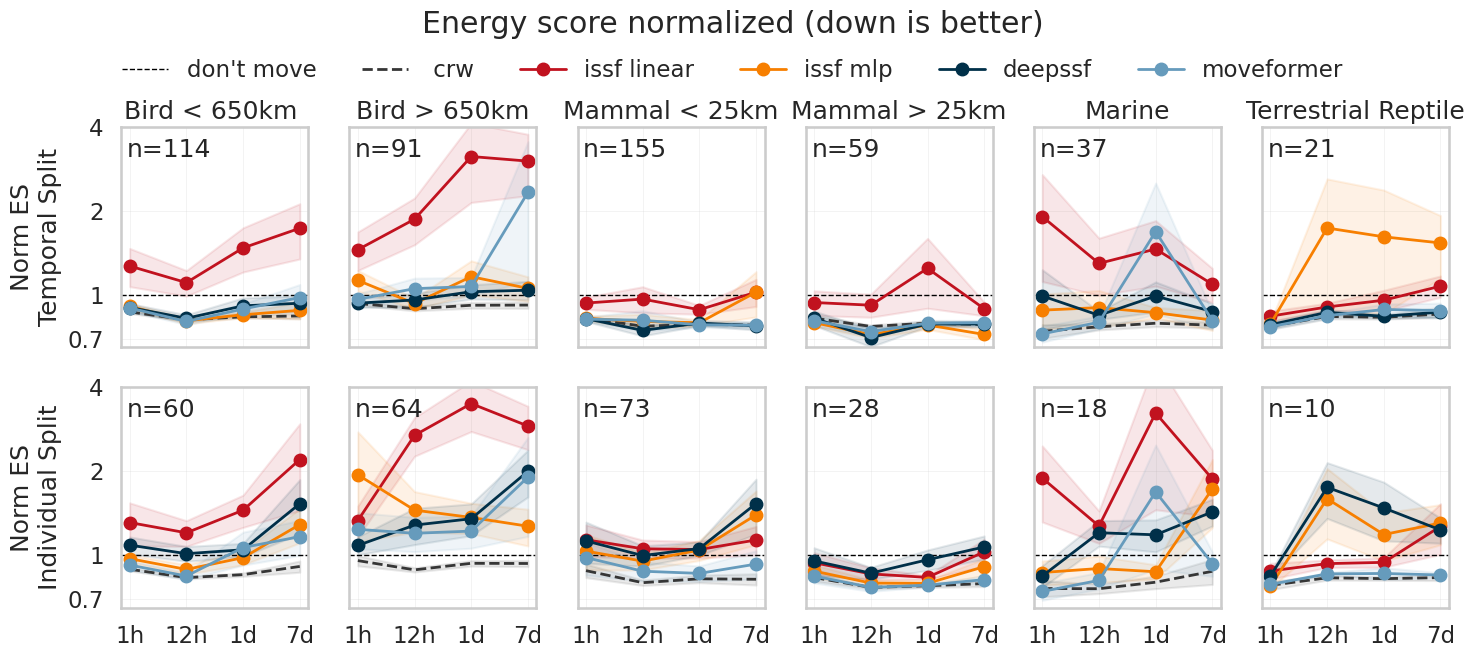

In [11]:
from matplotlib.ticker import FixedLocator, FuncFormatter

ROW_SPLITS = [
    ("test_temporal", "Temporal Split"),
    ("test_individual", "Individual Split"),
]

fig, axes = plt.subplots(2, 6, figsize=(15, 7), sharex=True, 
                         sharey=True
                         )

split_panel_counts = {
    (row.split_key, row.panel): int(row.n_test_individuals)
    for row in two_row_panel_counts_df.itertuples(index=False)
}


def plot_panel(ax: plt.Axes, panel: str, split_key: str) -> None:
    ax.axhline(1.0, color="black", linestyle="--", linewidth=1.0, label="don't move")
    panel_subset = two_row_aggregate_df[
        (two_row_aggregate_df["split_key"] == split_key) & (two_row_aggregate_df["panel"] == panel)
    ].copy()

    for method in PLOT_METHODS:
        method_rows = panel_subset[panel_subset["method"] == method].sort_values("x")
        if method_rows.empty:
            continue
        ax.plot(
            method_rows["x"],
            method_rows["mean_value"],
            marker=None if 'baseline' in method else "o",
            linewidth=2.0,
            color=METHOD_COLORS[method],
            label=_method_label(method),
            # markersize=5 if 'baseline' in method else 6,
            linestyle="--" if 'baseline' in method else None, 
        )

        ax.fill_between(
            method_rows["x"],
            method_rows["mean_value"] - method_rows["sem_value"],
            method_rows["mean_value"] + method_rows["sem_value"],
            color=METHOD_COLORS[method],
            alpha=0.1,
        )

    ax.set_xticks(range(len(TIMESCALE_ORDER)), TIMESCALE_ORDER)
    

    ax.set_ylim(0.65, 4) #1.15) #1.99)
    ax.set_yscale('log')

    # ax.set_ylim(0.65, 1.15) #1.15) #1.99)

    yticks = [0.7, 1, 2, 4]   # or [0.6, 1, 2, 4]
    ax.yaxis.set_major_locator(FixedLocator(yticks))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}"))
    ax.yaxis.set_minor_locator(FixedLocator([]))   # optional: remove minor ticks

    # ax.set_ylim(0.75, 1.1)

    
    ax.grid(True, linewidth=0.4, alpha=0.4)


for row_idx, (split_key, row_label) in enumerate(ROW_SPLITS):
    for col, panel in enumerate(PANEL_ORDER):
        ax = axes[row_idx, col]
        plot_panel(ax, panel, split_key)

        if row_idx == 0:
            ax.set_title(PANEL_TITLES[panel])

        ax.text(
            0.03,
            0.95,
            f"n={int(split_panel_counts.get((split_key, panel), 0))}",
            transform=ax.transAxes,
            ha="left",
            va="top",
        )

        if col == 0:
            ax.set_ylabel(f"Norm ES\n{row_label}")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(PLOT_METHODS) + 1, frameon=False, bbox_to_anchor=(0.5, 0.91))
fig.suptitle("Energy score normalized (down is better)", y=0.95)
fig.tight_layout(rect=(0, 0, 1, 0.94))

plt.savefig("ES-grouped-two-rows-log-withrw-v2-log.png")
plt.savefig("ES-grouped-two-rows-log-withrw-v2-log.pdf")

In [12]:
def _covariate_label(covariate_set: str) -> str:
    return {
        "lite" : "env lite", 
        "all_environmental": 'env all',
        "alphaearth_only": "alphaearth", 
        "alphaearth_and_marine": "alphaearth+marine",
        "all": 'env+alphaearth',
    }[covariate_set]
    # return covariate_set.replace("_", " ")


def covariate_comparison_study_ids(*, study_ids: list[str] | None = None) -> list[str]:
    return sorted(
        {
            str(run_payload.get("study_id", ""))
            for run_payload in planned_run_map("covariate_comparison", "alphaearth_and_marine_mini", study_ids=study_ids).values()
            if str(run_payload.get("study_id", ""))
        }
    )


def scan_covariate_comparison_runs(*, study_ids: list[str] | None = None) -> pd.DataFrame:
    run_rows: list[dict[str, object]] = []
    comparison_study_ids = covariate_comparison_study_ids(study_ids=study_ids)

    for experiment_name in ["main_results", "covariate_comparison", "alphaearth_and_marine_mini"]:
        for run_key, payload in completed_planned_runs(experiment_name, study_ids=comparison_study_ids).items():
            run_payload = dict(payload["run_payload"])
            latest_run = dict(payload["latest_run"])
            study_id = str(run_payload.get("study_id", ""))
            timescale = str(run_payload.get("timescale", ""))
            method = str(run_payload.get("method", ""))
            covariate_set = str(run_payload.get("covariate_set", ""))

            if timescale not in TIMESCALE_ORDER:
                continue
            if method not in [NORMALIZE_BY, "baseline_randomwalk", *COVARIATE_COMPARISON_METHODS]:
                continue
            if experiment_name == "main_results" and covariate_set != "all":
                continue
            if experiment_name == "covariate_comparison" and covariate_set == "all":
                continue
            if covariate_set not in COVARIATE_SET_ORDER:
                continue

            run_dir = RUNS_ROOT / run_key
            resolved_path = run_dir / "resolved_run.json"
            summary_path = run_dir / "final_metrics" / SPLIT_KEY / "summary.json"
            if not summary_path.exists():
                continue

            summary = json.loads(summary_path.read_text(encoding="utf-8"))
            if summary.get("energy_score") is None:
                continue

            run_rows.append(
                {
                    "run_dir": str(run_dir),
                    "run_key": run_key,
                    "study_id": study_id,
                    "timescale": timescale,
                    "covariate_set": covariate_set,
                    "method": method,
                    "completed_at": completed_at_for_run(latest_run, [resolved_path, summary_path]),
                    "energy_score": float(summary["energy_score"]),
                }
            )

    run_df = pd.DataFrame.from_records(run_rows)
    if run_df.empty:
        return run_df

    return (
        run_df.sort_values("completed_at")
        .drop_duplicates(["study_id", "timescale", "covariate_set", "method"], keep="last")
        .reset_index(drop=True)
    )


def build_covariate_normalized_energy_df(
    run_df: pd.DataFrame,
    study_summary_df: pd.DataFrame,
    methods: list[str],
) -> pd.DataFrame:
    baseline_df = run_df[(run_df["method"] == NORMALIZE_BY) & (run_df["covariate_set"] == "all")][
        ["study_id", "timescale", "energy_score"]
    ].rename(columns={"energy_score": "baseline_energy_score"})
    method_df = run_df[run_df["method"].isin(methods)].copy()
    normalized_df = method_df.merge(
        baseline_df,
        on=["study_id", "timescale"],
        how="inner",
        validate="many_to_one",
    )
    normalized_df = normalized_df[normalized_df["baseline_energy_score"] > 0].copy()
    normalized_df["value"] = normalized_df["energy_score"] / normalized_df["baseline_energy_score"]
    return normalized_df.merge(
        study_summary_df[["study_id", "study_name_v2", "study_species", "high_level_group", "distance_bin", "panel"]],
        on="study_id",
        how="inner",
        validate="many_to_one",
    )


covariate_run_df = scan_covariate_comparison_runs(study_ids=study_status_df["study_id"].dropna().tolist())
covariate_study_summary_df = study_status_df[study_status_df["panel"].notna()].copy()
covariate_normalized_energy_df = build_covariate_normalized_energy_df(
    covariate_run_df,
    covariate_study_summary_df,
    COVARIATE_COMPARISON_METHODS,
)
randomwalk_normalized_df = build_covariate_normalized_energy_df(
    covariate_run_df[covariate_run_df["covariate_set"] == "all"].copy(),
    covariate_study_summary_df,
    ["baseline_randomwalk"],
)
covariate_aggregate_df = (
    covariate_normalized_energy_df.groupby(["method", "panel", "covariate_set", "timescale"], as_index=False)
    .agg(
        mean_value=("value", "mean"),
        std_value=("value", "std"),
        n_studies=("study_id", "nunique"),
    )
)
covariate_aggregate_df["sem_value"] = covariate_aggregate_df["std_value"].fillna(0.0) / np.sqrt(
    covariate_aggregate_df["n_studies"].clip(lower=1)
)
covariate_aggregate_df["x"] = covariate_aggregate_df["timescale"].map(TIMESCALE_ORDER.index)
covariate_ylim_top = 2.0
if not covariate_aggregate_df.empty:
    covariate_ylim_top = max(2.0, float(covariate_aggregate_df["mean_value"].max()) * 1.05)

covariate_aggregate_df.sort_values(["method", "panel", "covariate_set", "x"]).head(20)


,method,panel,covariate_set,timescale,mean_value,std_value,n_studies,sem_value,x
2,deepssf,bird_long,all,1h,0.695601,NaN,1,0.000000,0
0,deepssf,bird_long,all,12h,0.697471,NaN,1,0.000000,1
1,deepssf,bird_long,all,1d,0.598125,NaN,1,0.000000,2
3,deepssf,bird_long,all,7d,0.965964,0.820608,2,0.580257,3
6,deepssf,bird_long,all_environmental,1h,0.710368,NaN,1,0.000000,0
4,deepssf,bird_long,all_environmental,12h,0.876336,0.166302,2,0.117593,1
5,deepssf,bird_long,all_environmental,1d,0.544270,NaN,1,0.000000,2
7,deepssf,bird_long,all_environmental,7d,0.531555,0.385131,2,0.272329,3
10,deepssf,bird_long,alphaearth_and_marine,1h,0.530558,NaN,1,0.000000,0
8,deepssf,bird_long,alphaearth_and_marine,12h,0.694176,0.181864,2,0.128597,1


In [13]:
covariate_paired_df = covariate_normalized_energy_df.merge(
    covariate_normalized_energy_df[
        covariate_normalized_energy_df["covariate_set"] == "all"
    ][["study_id", "method", "timescale", "value"]].rename(columns={"value": "all_value"}),
    on=["study_id", "method", "timescale"],
    how="inner",
    validate="many_to_one",
)
covariate_paired_df["delta_vs_all"] = covariate_paired_df["value"] - covariate_paired_df["all_value"]
covariate_paired_df["pct_vs_all"] = covariate_paired_df["value"] / covariate_paired_df["all_value"] - 1.0
covariate_paired_df["wins_vs_all"] = covariate_paired_df["delta_vs_all"] < 0

covariate_delta_summary_df = (
    covariate_paired_df.groupby(["method", "panel", "covariate_set"], as_index=False)
    .agg(
        mean_value=("value", "mean"),
        mean_delta_vs_all=("delta_vs_all", "mean"),
        mean_pct_vs_all=("pct_vs_all", "mean"),
        median_pct_vs_all=("pct_vs_all", "median"),
        win_rate_vs_all=("wins_vs_all", "mean"),
        n_pairs=("wins_vs_all", "size"),
    )
)
covariate_delta_summary_df["panel_title"] = covariate_delta_summary_df["panel"].map(PANEL_TITLES)
covariate_delta_summary_df["method_label"] = covariate_delta_summary_df["method"].map(_method_label)
covariate_delta_summary_df["covariate_label"] = covariate_delta_summary_df["covariate_set"].map(_covariate_label)

covariate_method_summary_df = (
    covariate_paired_df.groupby(["method", "covariate_set"], as_index=False)
    .agg(
        mean_pct_vs_all=("pct_vs_all", "mean"),
        median_pct_vs_all=("pct_vs_all", "median"),
        win_rate_vs_all=("wins_vs_all", "mean"),
        n_pairs=("wins_vs_all", "size"),
    )
)
covariate_method_summary_df["method_label"] = covariate_method_summary_df["method"].map(_method_label)
covariate_method_summary_df["covariate_label"] = covariate_method_summary_df["covariate_set"].map(_covariate_label)

covariate_best_panel_df = (
    covariate_delta_summary_df.sort_values(["method", "panel", "mean_value", "covariate_set"])
    .groupby(["method", "panel"], as_index=False)
    .first()
)
covariate_best_panel_df["improvement_pct"] = -100.0 * covariate_best_panel_df["mean_pct_vs_all"]

covariate_delta_summary_df[
    [
        "method_label",
        "panel_title",
        "covariate_label",
        "mean_pct_vs_all",
        "win_rate_vs_all",
        "n_pairs",
    ]
].sort_values(["method_label", "panel_title", "covariate_label"]).head(24)


,method_label,panel_title,covariate_label,mean_pct_vs_all,win_rate_vs_all,n_pairs
8,deepssf,Bird < 650km,alphaearth,-0.129839,1.000000,8
7,deepssf,Bird < 650km,alphaearth+marine,-0.052885,0.625000,8
6,deepssf,Bird < 650km,env all,0.011590,0.375000,8
9,deepssf,Bird < 650km,env lite,0.006838,0.375000,8
5,deepssf,Bird < 650km,env+alphaearth,0.000000,0.000000,8
3,deepssf,Bird > 650km,alphaearth,-0.214935,1.000000,5
2,deepssf,Bird > 650km,alphaearth+marine,-0.095968,0.800000,5
1,deepssf,Bird > 650km,env all,-0.157796,0.600000,5
4,deepssf,Bird > 650km,env lite,-0.014573,0.600000,5
0,deepssf,Bird > 650km,env+alphaearth,0.000000,0.000000,5


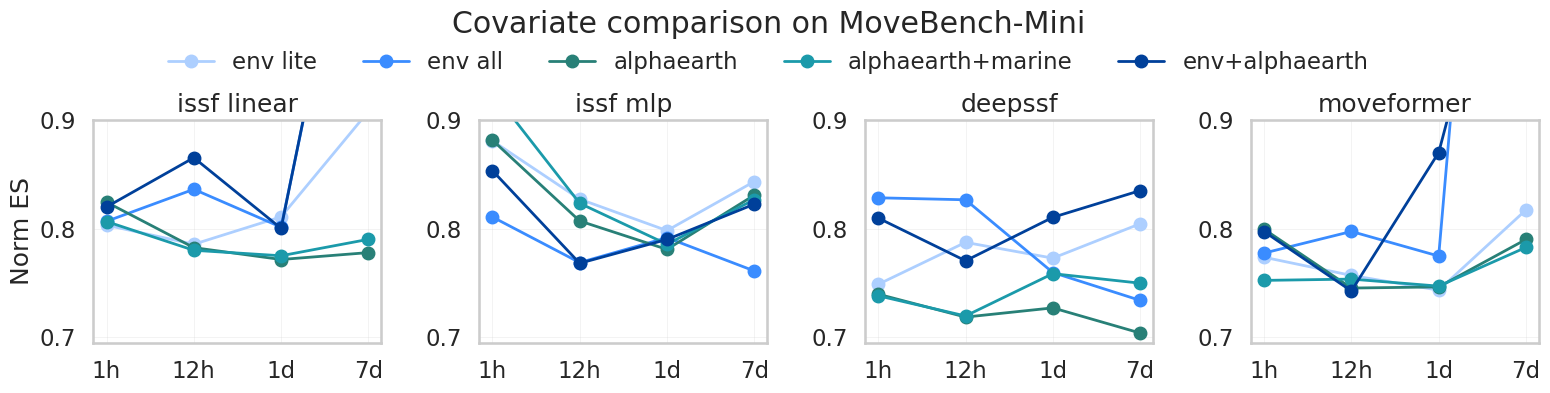

In [14]:
covariate_collapsed_aggregate_df = (
    covariate_normalized_energy_df.groupby(["method", "covariate_set", "timescale"], as_index=False)
    .agg(
        mean_value=("value", "mean"),
        std_value=("value", "std"),
        n_studies=("study_id", "nunique"),
    )
)
covariate_collapsed_aggregate_df["sem_value"] = (
    covariate_collapsed_aggregate_df["std_value"].fillna(0.0)
    / np.sqrt(covariate_collapsed_aggregate_df["n_studies"].clip(lower=1))
)
covariate_collapsed_aggregate_df["x"] = covariate_collapsed_aggregate_df["timescale"].map(TIMESCALE_ORDER.index)
covariate_collapsed_ylim_top = 2.0
if not covariate_collapsed_aggregate_df.empty:
    covariate_collapsed_ylim_top = max(
        2.0,
        float(covariate_collapsed_aggregate_df["mean_value"].max()) * 1.05,
    )

fig, axes = plt.subplots(1, len(COVARIATE_COMPARISON_METHODS), figsize=(16, 4), 
                         sharex=True, 
                        #  sharey=True
                         )

for col, method in enumerate(COVARIATE_COMPARISON_METHODS):
    ax = axes[col]
    # ax.axhline(1.0, color="black", linestyle="--", linewidth=1.0, label="don't move")
    method_subset = covariate_collapsed_aggregate_df[
        covariate_collapsed_aggregate_df["method"] == method
    ].copy()

    for covariate_set in COVARIATE_SET_ORDER:
        covariate_rows = method_subset[method_subset["covariate_set"] == covariate_set].sort_values("x")
        if covariate_rows.empty:
            continue
        ax.plot(
            covariate_rows["x"],
            covariate_rows["mean_value"],
            marker=None if 'baseline' in method else "o",
            linewidth=2.0,
            color=COVARIATE_COLORS[covariate_set],
            label=_covariate_label(covariate_set),
            linestyle="--" if 'baseline' in method else None, 
        )


        # ax.fill_between(
        #     covariate_rows["x"],
        #     covariate_rows["mean_value"] - covariate_rows["sem_value"],
        #     covariate_rows["mean_value"] + covariate_rows["sem_value"],
        #     color=COVARIATE_COLORS[covariate_set],
        #     alpha=0.15,
        # )

    ax.set_xticks(range(len(TIMESCALE_ORDER)), TIMESCALE_ORDER)
    # ax.set_ylim(0.0, covariate_collapsed_ylim_top)
    ax.set_ylim(0.695, 0.9)
    ax.grid(True, linewidth=0.4, alpha=0.4)
    ax.set_title(_method_label(method))

    # n_studies = int(method_subset["n_studies"].max()) if not method_subset.empty else 0
    # ax.text(
    #     0.03,
    #     0.95,
    #     f"n<={n_studies} studies / timescale",
    #     transform=ax.transAxes,
    #     ha="left",
    #     va="top",
    #     fontsize=9,
    # )

axes[0].set_ylabel("Norm ES")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(COVARIATE_SET_ORDER) + 1, frameon=False, bbox_to_anchor=(0.5, 0.95))
fig.suptitle("Covariate comparison on MoveBench-Mini", y=1.0)
fig.tight_layout()

plt.savefig('cov-1.pdf', bbox_inches='tight', dpi=300)

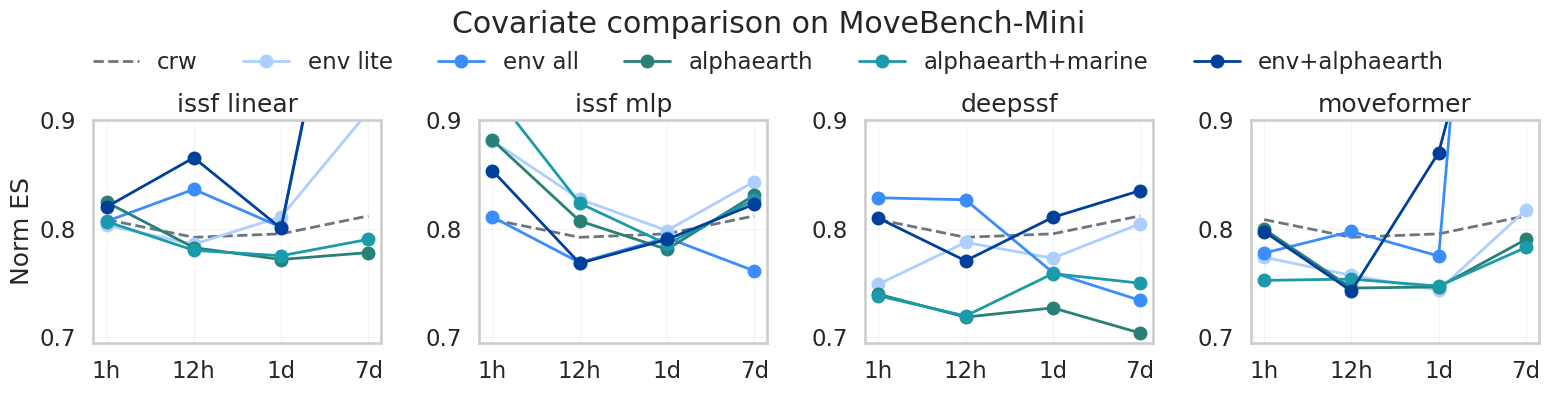

In [15]:
randomwalk_collapsed_df = (
    randomwalk_normalized_df.groupby(["timescale"], as_index=False)
    .agg(
        mean_value=("value", "mean"),
        std_value=("value", "std"),
        n_studies=("study_id", "nunique"),
    )
)
randomwalk_collapsed_df["sem_value"] = (
    randomwalk_collapsed_df["std_value"].fillna(0.0)
    / np.sqrt(randomwalk_collapsed_df["n_studies"].clip(lower=1))
)
randomwalk_collapsed_df["x"] = randomwalk_collapsed_df["timescale"].map(TIMESCALE_ORDER.index)
randomwalk_collapsed_df = randomwalk_collapsed_df.sort_values("x").reset_index(drop=True)

fig, axes = plt.subplots(
    1,
    len(COVARIATE_COMPARISON_METHODS),
    figsize=(16, 4),
    sharex=True,
    # sharey=True
)

for col, method in enumerate(COVARIATE_COMPARISON_METHODS):
    ax = axes[col]
    method_subset = covariate_collapsed_aggregate_df[
        covariate_collapsed_aggregate_df["method"] == method
    ].copy()

    if not randomwalk_collapsed_df.empty:
        ax.plot(
            randomwalk_collapsed_df["x"],
            randomwalk_collapsed_df["mean_value"],
            marker=None, #"o",
            linewidth=2.0,
            linestyle="--",
            color="#6c757d",
            label="crw",
        )

    for covariate_set in COVARIATE_SET_ORDER:
        covariate_rows = method_subset[
            method_subset["covariate_set"] == covariate_set
        ].sort_values("x")
        if covariate_rows.empty:
            continue
        ax.plot(
            covariate_rows["x"],
            covariate_rows["mean_value"],
            marker="o",
            linewidth=2.0,
            color=COVARIATE_COLORS[covariate_set],
            label=_covariate_label(covariate_set),
        )

    

    ax.set_xticks(range(len(TIMESCALE_ORDER)), TIMESCALE_ORDER)
    # ax.set_ylim(0.0, covariate_collapsed_ylim_top)
    ax.set_ylim(0.695, 0.9)
    ax.grid(True, linewidth=0.4, alpha=0.4)
    ax.set_title(_method_label(method))

axes[0].set_ylabel("Norm ES")

handles, labels = [], []
for ax in axes:
    h, l = ax.get_legend_handles_labels()
    for handle, label in zip(h, l):
        if label not in labels:
            handles.append(handle)
            labels.append(label)

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=len(COVARIATE_SET_ORDER) + 1,
    frameon=False,
    bbox_to_anchor=(0.5, 0.95),
)
fig.suptitle("Covariate comparison on MoveBench-Mini", y=1.0)
fig.tight_layout()

plt.savefig("cov-1-withrw.pdf", bbox_inches="tight", dpi=300)
plt.savefig("cov-1-withrw.png", bbox_inches="tight", dpi=300)

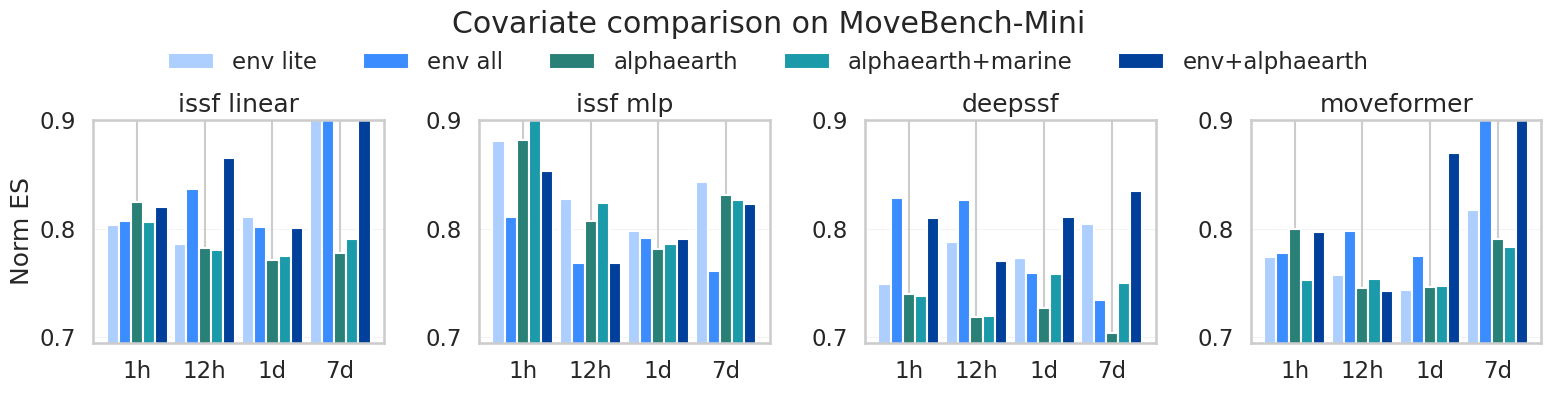

In [16]:
covariate_collapsed_aggregate_df = (
      covariate_normalized_energy_df.groupby(["method", "covariate_set", "timescale"], as_index=False)
      .agg(
          mean_value=("value", "mean"),
          std_value=("value", "std"),
          n_studies=("study_id", "nunique"),
      )
  )
covariate_collapsed_aggregate_df["sem_value"] = (
    covariate_collapsed_aggregate_df["std_value"].fillna(0.0)
    / np.sqrt(covariate_collapsed_aggregate_df["n_studies"].clip(lower=1))
)
covariate_collapsed_aggregate_df["x"] = covariate_collapsed_aggregate_df["timescale"].map(TIMESCALE_ORDER.index)
covariate_collapsed_ylim_top = 2.0
if not covariate_collapsed_aggregate_df.empty:
    covariate_collapsed_ylim_top = max(
        2.0,
        float(covariate_collapsed_aggregate_df["mean_value"].max()) * 1.05,
    )

fig, axes = plt.subplots(
    1,
    len(COVARIATE_COMPARISON_METHODS),
    figsize=(16, 4),
    sharex=True,
    # sharey=True
)

bar_width = 0.18
x_positions = np.arange(len(TIMESCALE_ORDER))
bar_offsets = np.linspace(
    -bar_width * (len(COVARIATE_SET_ORDER) - 1) / 2.0,
    bar_width * (len(COVARIATE_SET_ORDER) - 1) / 2.0,
    len(COVARIATE_SET_ORDER),
)

for col, method in enumerate(COVARIATE_COMPARISON_METHODS):
    ax = axes[col]
    method_subset = covariate_collapsed_aggregate_df[
        covariate_collapsed_aggregate_df["method"] == method
    ].copy()

    for offset, covariate_set in zip(bar_offsets, COVARIATE_SET_ORDER):
        covariate_rows = (
            method_subset[method_subset["covariate_set"] == covariate_set]
            .set_index("timescale")
            .reindex(TIMESCALE_ORDER)
        )
        if covariate_rows["mean_value"].isna().all():
            continue

        ax.bar(
            x_positions + offset,
            covariate_rows["mean_value"],
            width=bar_width,
            color=COVARIATE_COLORS[covariate_set],
            label=_covariate_label(covariate_set),
            # yerr=covariate_rows["sem_value"],
            # capsize=3,
        )

    ax.set_xticks(x_positions, TIMESCALE_ORDER)
    # ax.set_ylim(0.0, covariate_collapsed_ylim_top)
    ax.set_ylim(0.695, 0.9)
    ax.grid(True, linewidth=0.4, alpha=0.4, axis="y")
    ax.set_title(_method_label(method))

axes[0].set_ylabel("Norm ES")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=len(COVARIATE_SET_ORDER),
    frameon=False,
    bbox_to_anchor=(0.5, 0.95),
)
fig.suptitle("Covariate comparison on MoveBench-Mini", y=1.0)
fig.tight_layout()

plt.savefig('cov-2.png')

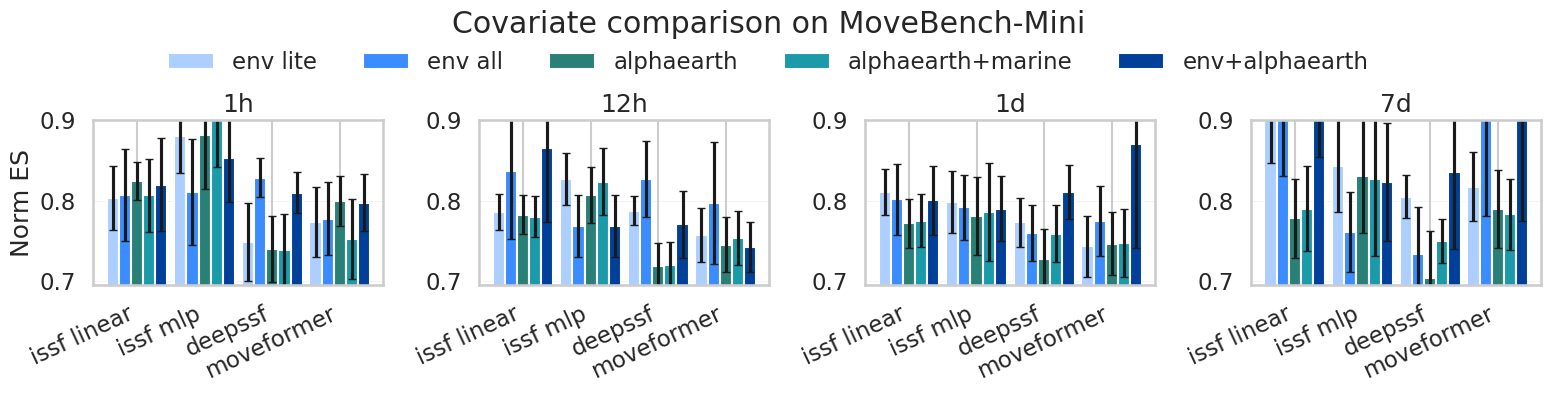

In [17]:
fig, axes = plt.subplots(1, len(TIMESCALE_ORDER), figsize=(16, 4), 
                        #  sharey=True
                         )
bar_width = 0.18
method_positions = np.arange(len(COVARIATE_COMPARISON_METHODS))
bar_offsets = np.linspace(
    -bar_width * (len(COVARIATE_SET_ORDER) - 1) / 2.0,
    bar_width * (len(COVARIATE_SET_ORDER) - 1) / 2.0,
    len(COVARIATE_SET_ORDER),
)

for ax, timescale in zip(axes, TIMESCALE_ORDER):
    timescale_subset = covariate_collapsed_aggregate_df[
        covariate_collapsed_aggregate_df["timescale"] == timescale
    ].copy()

    for offset, covariate_set in zip(bar_offsets, COVARIATE_SET_ORDER):
        covariate_subset = (
            timescale_subset[timescale_subset["covariate_set"] == covariate_set]
            .set_index("method")
            .reindex(COVARIATE_COMPARISON_METHODS)
        )
        ax.bar(
            method_positions + offset,
            covariate_subset["mean_value"],
            width=bar_width,
            color=COVARIATE_COLORS[covariate_set],
            label=_covariate_label(covariate_set),
            yerr=covariate_subset["sem_value"],
            capsize=3,
        )

    ax.axhline(1.0, color="black", linestyle="--", linewidth=1.0)
    ax.set_title(timescale)
    ax.set_xticks(
        method_positions,
        [_method_label(method) for method in COVARIATE_COMPARISON_METHODS],
        rotation=25,
        ha="right",
    )
    ax.set_ylim(0.695, 0.9) #covariate_collapsed_ylim_top)
    ax.grid(True, axis="y", linewidth=0.4, alpha=0.4)

axes[0].set_ylabel("Norm ES")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=len(COVARIATE_SET_ORDER),
    frameon=False,
    bbox_to_anchor=(0.5, 0.95),
)
fig.suptitle(
    "Covariate comparison on MoveBench-Mini",
    y=1.0,
)
fig.tight_layout()

plt.savefig('cov-3.png')